In [1]:
import pandas as pd

In [2]:
uds = pd.read_csv("udslong_imputed.csv", dtype={"NACCID": "string"})
mri = pd.read_csv("mriscanclean.csv", dtype={"NACCID": "string"})

In [3]:
print("UDS:", uds.shape)
print("MRI:", mri.shape)

UDS: (1237, 180)
MRI: (1237, 126)


In [4]:
for name, df in [("UDS", uds), ("MRI", mri)]:
    ids = df["NACCID"]
    print(name)
    print("شناسه‌های یکتا:", ids.nunique())
    print("شناسه‌های خالی:", ids.isna().sum())
    print("ردیف‌های دارای شناسهٔ تکراری:", ids.duplicated(keep=False).sum())

UDS
شناسه‌های یکتا: 1237
شناسه‌های خالی: 0
ردیف‌های دارای شناسهٔ تکراری: 0
MRI
شناسه‌های یکتا: 1237
شناسه‌های خالی: 0
ردیف‌های دارای شناسهٔ تکراری: 0


In [5]:
merged = uds.merge(
    mri[["NACCID", "LH_ENTORHINAL_AVGTH"]],
    on="NACCID",
    how="outer",
    validate="one_to_one",
    indicator=True,
)

print(merged["_merge"].value_counts())

_merge
both          1237
left_only        0
right_only       0
Name: count, dtype: int64


In [6]:
uds["MOCATOTS"]

0       25.0
1       24.0
2       24.0
3       26.0
4       21.0
        ... 
1232    22.6
1233    26.0
1234    30.0
1235    26.0
1236    29.0
Name: MOCATOTS, Length: 1237, dtype: float64

## بررسی کیفیت و آماده‌سازی داده
اتصال اولیهٔ بالا پوشش شناسه‌ها را نشان می‌دهد. در جدول زیر ضخامت هر دو سمت را وارد می‌کنیم.

In [7]:
thickness_cols = ["LH_ENTORHINAL_AVGTH", "RH_ENTORHINAL_AVGTH"]

matched = uds.merge(
    mri[["NACCID", *thickness_cols]],
    on="NACCID",
    how="inner",
    validate="one_to_one",
)

print("تعداد افراد مشترک:", len(matched))

تعداد افراد مشترک: 1237


In [8]:
moca = matched["MOCATOTS"]
in_range = moca.between(0, 30)
outside_range = moca.notna() & ~in_range
fractional_in_range = in_range & moca.mod(1).ne(0)

print("خانه‌های خالی MoCA:", moca.isna().sum())
print("مقادیر خارج از بازه:", outside_range.sum())
print(moca[outside_range].value_counts().sort_index())
print("مقادیر اعشاری داخل بازه:", fractional_in_range.sum())

for col in thickness_cols:
    values = matched[col]
    print(col)
    print("خانه‌های خالی:", values.isna().sum())
    print("مقادیر صفر یا منفی:", values.le(0).sum())
    print("کمینه و بیشینه:", values.min(), values.max())

print("ردیف‌های کاملاً تکراری UDS:", uds.duplicated().sum())
print("ردیف‌های کاملاً تکراری MRI:", mri.duplicated().sum())
status_uds = uds.set_index("NACCID")["NACCUDSD"].sort_index()
status_mri = mri.set_index("NACCID")["NACCUDSD"].sort_index()
print("ناهمخوانی کد وضعیت شناختی در افراد مشترک:",
      status_uds.ne(status_mri).sum())

خانه‌های خالی MoCA: 0
مقادیر خارج از بازه: 9
MOCATOTS
30.8    1
34.2    1
38.8    1
39.4    2
88.0    4
Name: count, dtype: int64
مقادیر اعشاری داخل بازه: 244
LH_ENTORHINAL_AVGTH
خانه‌های خالی: 0
مقادیر صفر یا منفی: 0
کمینه و بیشینه: 0.878 3.979
RH_ENTORHINAL_AVGTH
خانه‌های خالی: 0
مقادیر صفر یا منفی: 0
کمینه و بیشینه: 0.729 3.967
ردیف‌های کاملاً تکراری UDS: 0
ردیف‌های کاملاً تکراری MRI: 0
ناهمخوانی کد وضعیت شناختی در افراد مشترک: 0


In [9]:
analysis_data = matched.copy()
moca_raw = analysis_data["MOCATOTS"]
analysis_data["MoCA_analysis"] = moca_raw.where(moca_raw.between(0, 30))

asym_col = "entorhinal_asymmetry_mm"
analysis_data[asym_col] = (
    analysis_data[thickness_cols[0]] - analysis_data[thickness_cols[1]]
).abs()

has_pair = (
    analysis_data["MoCA_analysis"].notna()
    & analysis_data[asym_col].notna()
)

print("کل افراد در جدول:", len(analysis_data))
print("افراد دارای هر دو مقدار برای بررسی رابطه:", has_pair.sum())
print("افراد بدون جفت قابل استفاده:", (~has_pair).sum())

کل افراد در جدول: 1237
افراد دارای هر دو مقدار برای بررسی رابطه: 1228
افراد بدون جفت قابل استفاده: 9


## آمار توصیفی و فراوانی گروه‌ها

In [10]:
numeric_cols = [*thickness_cols, asym_col, "MoCA_analysis"]
summary = analysis_data[numeric_cols].describe().T
summary["IQR"] = summary["75%"] - summary["25%"]
summary["count"] = summary["count"].astype(int)
display(summary.round(3))

status_labels = {
    1: "شناخت طبیعی",
    2: "اختلال شناختی بدون احراز معیارهای MCI",
    3: "اختلال شناختی خفیف (MCI)",
    4: "دمانس",
}

status_counts = analysis_data["NACCUDSD"].value_counts(dropna=False).sort_index()
status_table = status_counts.to_frame("تعداد")
status_table.insert(0, "گروه", status_table.index.map(status_labels).fillna("نامشخص"))
status_table["درصد"] = (100 * status_table["تعداد"] / len(analysis_data)).round(2)
display(status_table)

q1 = summary.loc[asym_col, "25%"]
q3 = summary.loc[asym_col, "75%"]
iqr = summary.loc[asym_col, "IQR"]
upper_fence = q3 + 1.5 * iqr
print("مرز بالایی بررسی مقادیر دورافتاده:", round(upper_fence, 4))
print("تعداد اختلاف‌های بالاتر از مرز:", analysis_data[asym_col].gt(upper_fence).sum())

مرز بالایی بررسی مقادیر دورافتاده: 0.7295
تعداد اختلاف‌های بالاتر از مرز: 50


,count,mean,std,min,25%,50%,75%,max,IQR
LH_ENTORHINAL_AVGTH,1237,2.970,0.384,0.878,2.763,3.021,3.228,3.979,0.465
RH_ENTORHINAL_AVGTH,1237,3.058,0.401,0.729,2.852,3.097,3.318,3.967,0.466
entorhinal_asymmetry_mm,1237,0.254,0.231,0.000,0.092,0.201,0.347,2.494,0.255
MoCA_analysis,1228,24.393,4.425,0.000,23.000,25.400,27.000,30.000,4.000


,گروه,تعداد,درصد
NACCUDSD,,,
1.0,شناخت طبیعی,847,68.47
2.0,اختلال شناختی بدون احراز معیارهای MCI,7,0.57
3.0,اختلال شناختی خفیف (MCI),252,20.37
4.0,دمانس,131,10.59


## چهار نمودار فاز اول

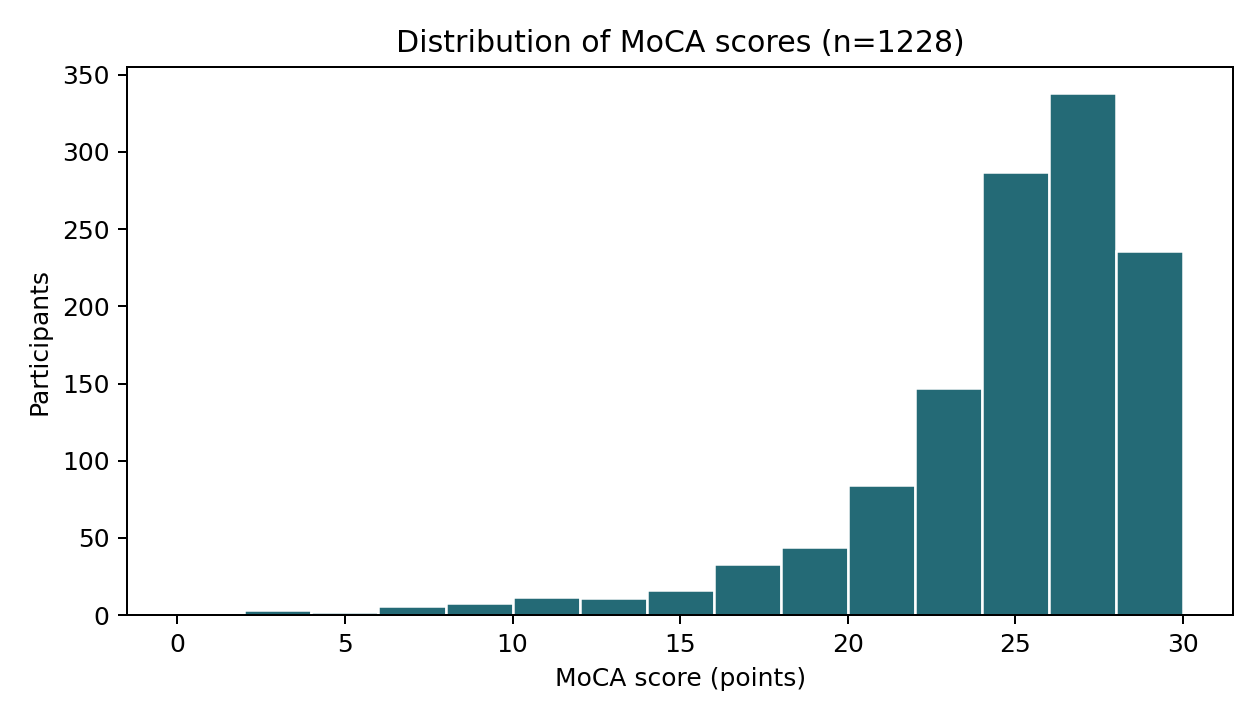

In [11]:
import matplotlib.pyplot as plt

moca_scores = analysis_data["MoCA_analysis"].dropna()
fig, ax = plt.subplots(figsize=(7, 4))
ax.hist(moca_scores, bins=range(0, 32, 2), color="#246A76", edgecolor="white")
ax.set(title=f"Distribution of MoCA scores (n={len(moca_scores)})",
       xlabel="MoCA score (points)", ylabel="Participants")
fig.tight_layout()
plt.show()

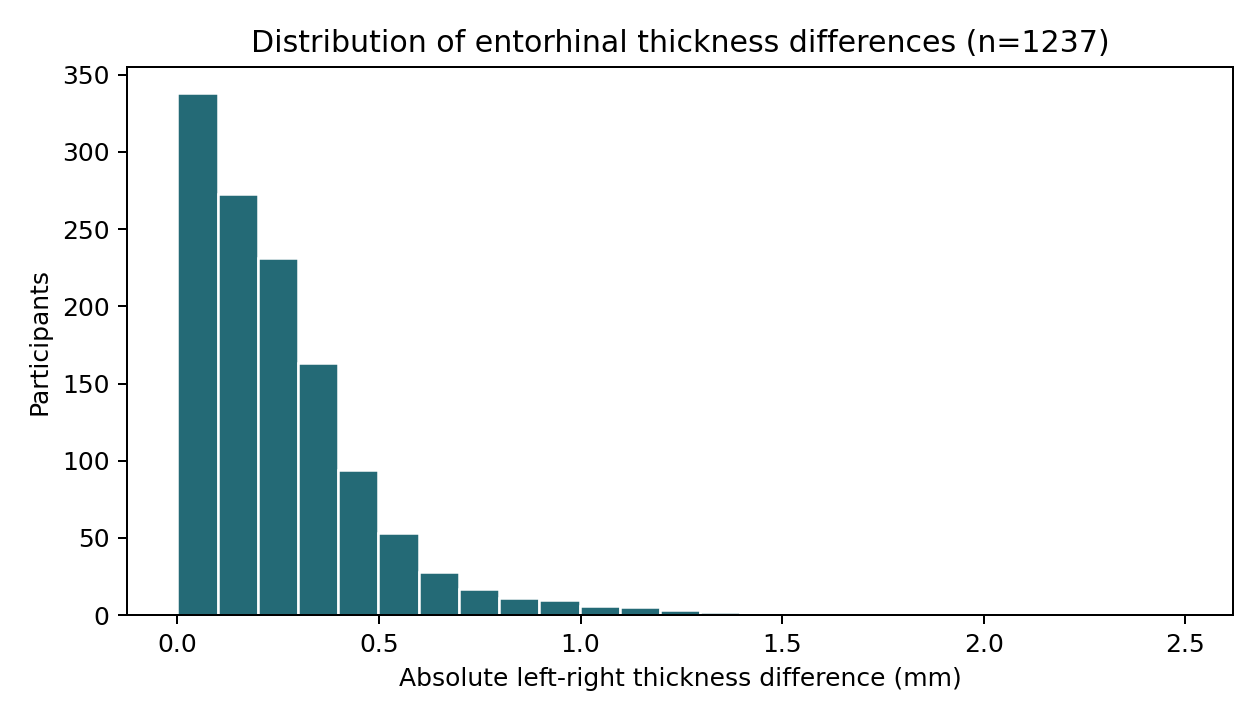

In [12]:
asymmetry = analysis_data[asym_col].dropna()
fig, ax = plt.subplots(figsize=(7, 4))
ax.hist(asymmetry, bins=25, color="#246A76", edgecolor="white")
ax.set(title=f"Distribution of entorhinal thickness differences (n={len(asymmetry)})",
       xlabel="Absolute left-right thickness difference (mm)", ylabel="Participants")
fig.tight_layout()
plt.show()

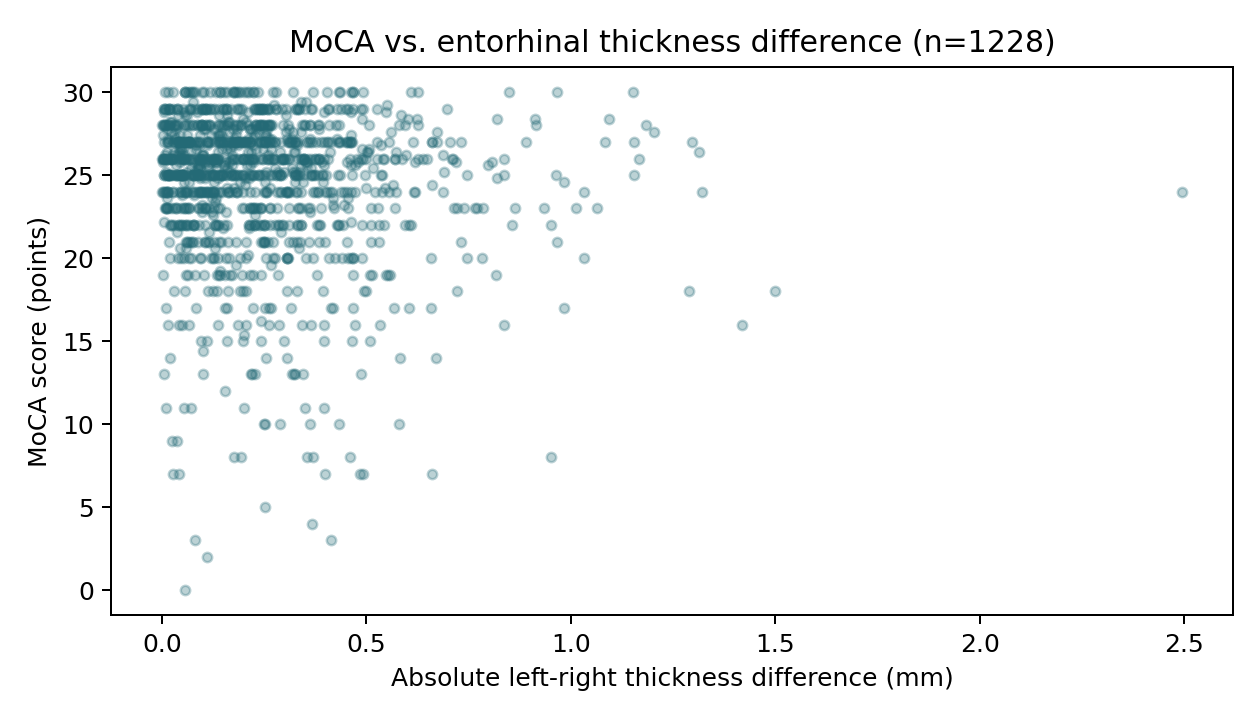

In [13]:
paired = analysis_data.loc[has_pair]
fig, ax = plt.subplots(figsize=(7, 4))
ax.scatter(paired[asym_col], paired["MoCA_analysis"], s=14, alpha=0.30, color="#246A76")
ax.set(title=f"MoCA vs. entorhinal thickness difference (n={len(paired)})",
       xlabel="Absolute left-right thickness difference (mm)", ylabel="MoCA score (points)")
fig.tight_layout()
plt.show()

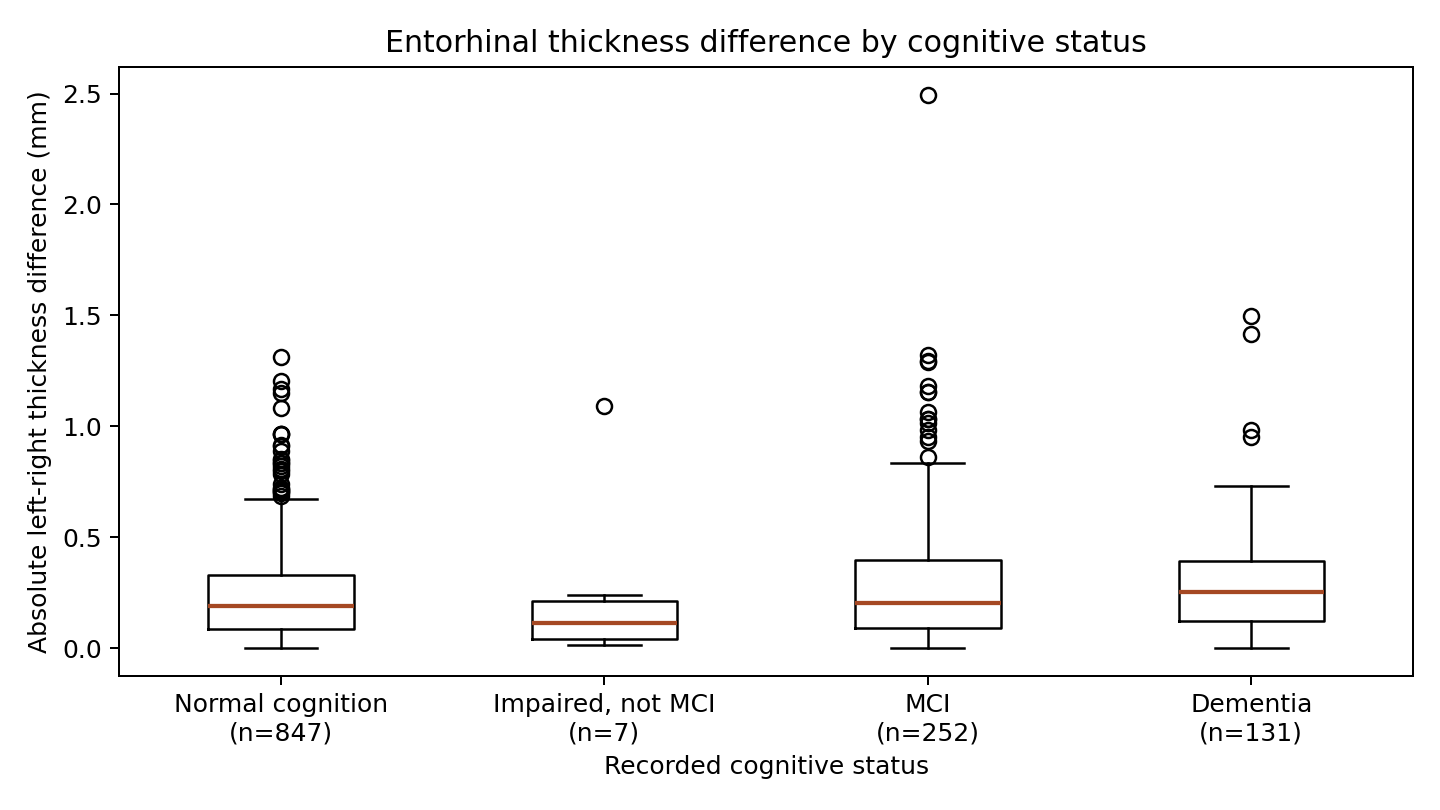

,n,median_mm
1,847,0.191
2,7,0.116
3,252,0.206
4,131,0.253


In [14]:
status_codes = [1, 2, 3, 4]
group_names = ["Normal cognition", "Impaired, not MCI", "MCI", "Dementia"]
group_values = [
    analysis_data.loc[analysis_data["NACCUDSD"].eq(code), asym_col].dropna()
    for code in status_codes
]
labels = [f"{name}\n(n={len(values)})" for name, values in zip(group_names, group_values)]

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.boxplot(group_values, medianprops={"color": "#A54823", "linewidth": 1.7})
ax.set_xticks(range(1, len(labels) + 1))
ax.set_xticklabels(labels)
ax.set(title="Entorhinal thickness difference by cognitive status",
       xlabel="Recorded cognitive status",
       ylabel="Absolute left-right thickness difference (mm)")
fig.tight_layout()
plt.show()

group_summary = pd.DataFrame({
    "n": [len(values) for values in group_values],
    "median_mm": [values.median() for values in group_values],
}, index=status_codes)
display(group_summary.round(3))

## خلاصهٔ رابطه و کنترل نهایی

In [15]:
thickness_groups = pd.qcut(paired[asym_col], q=4, labels=["Q1", "Q2", "Q3", "Q4"])
moca_by_thickness = paired.groupby(thickness_groups, observed=True).agg(
    n=("MoCA_analysis", "size"),
    min_mm=(asym_col, "min"),
    max_mm=(asym_col, "max"),
    median_MoCA=("MoCA_analysis", "median"),
)
display(moca_by_thickness.round(3))

assert len(analysis_data) == len(matched) == 1237
assert analysis_data["NACCID"].is_unique
assert analysis_data[matched.columns].equals(matched)
assert has_pair.sum() == 1228
assert (~has_pair).sum() == 9
assert moca_by_thickness["n"].sum() == has_pair.sum()
assert sum(len(values) for values in group_values) == len(analysis_data)

print("کنترل نهایی انجام شد.")

کنترل نهایی انجام شد.


,n,min_mm,max_mm,median_MoCA
entorhinal_asymmetry_mm,,,,
Q1,309,0.001,0.092,25.4
Q2,306,0.093,0.203,25.8
Q3,306,0.204,0.347,25.4
Q4,307,0.348,2.494,25.0
